# HEART – Machine Learning & Explainable AI (XAI) for ECG Arrhythmia Classification
**Students:** Benedetta Tintori, Michele Ivo Galella  
**Course:** Data Mining and Machine Learning, University of Pisa  

This notebook implements the complete, end-to-end machine learning classification and clinical explainability pipeline for heartbeat arrhythmia recognition using the MIT-BIH Arrhythmia Database.

The pipeline comprises:
1. **Data Preprocessing & Scaling**: Bandpass filtering, peak alignment, standard mapping, scaling, and training set balancing.
2. **Multi-Model Training**: Training and optimizing three distinct architectures: **Random Forest (RF)**, **Support Vector Machine (SVM)**, and **XGBoost Classifier**.
3. **Optimized Soft Voting Ensemble**: A weighted combination of all three models post-processed with class-specific probability multipliers to combat clinical alarm fatigue.
4. **Clinical Explainability (XAI)**: Measuring feature importances (Permutation Importance, SHAP) and plotting 2D real-feature decision boundaries to align model outputs with electrophysiological domain knowledge.


In [ ]:
%pip install -r ../requirements.txt

In [1]:
import pandas as pd
import numpy as np
import os
import time
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, LabelEncoder
from imblearn.under_sampling import RandomUnderSampler
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, f1_score, precision_score, recall_score
import shap

# Set plotting style for premium aesthetics
sns.set_theme(style="whitegrid")
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Inter', 'DejaVu Sans', 'Arial', 'Liberation Sans']
plt.rcParams['axes.edgecolor'] = '#CCCCCC'
plt.rcParams['axes.linewidth'] = 0.8


/Users/migalella/miniconda3/envs/dmml_env/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Path Resolution and Data Loading
We resolve the feature data paths locally on the workspace.


In [3]:
# Try multiple local paths for compatibility
possible_dirs = [
    '../data',
    './data'
]
data_dir = None
for d in possible_dirs:
    if os.path.exists(d):
        data_dir = d
        break
if data_dir is None:
    raise FileNotFoundError("Could not find data directory in any standard location!")
print(f"Data directory successfully resolved to: {data_dir}")

# Load SOTA feature dataset
df_features = pd.read_csv(os.path.join(data_dir, 'ECG_Features_Complete_SOTA.csv'))
print(f"Loaded dataset containing {df_features.shape[0]} samples and {df_features.shape[1]} features.")


Data directory successfully resolved to: ../data
Loaded dataset containing 96832 samples and 13 features.


## 2. Label Mapping (AAMI Standard) and Data Cleaning
We map the 19 standard PhysioNet annotation symbols into the 5 AAMI macro-classes.
- **N**: Normal and Branch Block beats (`N`, `L`, `R`, `e`, `j`)
- **S**: Supraventricular Ectopic beats (`A`, `a`, `J`, `S`)
- **V**: Premature Ventricular Contractions / Ectopics (`V`, `E`)
- **F**: Fusion beats (`F`)
- **Q**: Pacemaker/Unclassifiable beats (`/`, `f`, `Q`)

Consistent with clinical benchmarks and inter-patient split standards, we drop class **Q** as it corresponds to artifacts or artificial cardiac pacing.


In [4]:
aami_mapping = {
    'N': 'N', 'L': 'N', 'R': 'N', 'e': 'N', 'j': 'N',
    'A': 'S', 'a': 'S', 'J': 'S', 'S': 'S',
    'V': 'V', 'E': 'V', 'F': 'F'
}
df_features['AAMI_Class'] = df_features['Label'].map(aami_mapping)
# Drop unmapped / NaN (including Q class and artifacts)
df_features = df_features.dropna(subset=['AAMI_Class'])

print("\nAAMI Class distribution across full dataset:")
print(df_features['AAMI_Class'].value_counts())



AAMI Class distribution across full dataset:
AAMI_Class
N    87791
V     5615
S     2643
F      783
Name: count, dtype: int64


## 3. Inter-Patient Data Split and Scaling
To prevent severe data leakage, we use the standard **Inter-Patient split (De Chazal et al.)**.
- **DS1 (Train Set):** Beats from 22 records (`101`, `106`, etc.)
- **DS2 (Test Set):** Beats from 23 records (`100`, `103`, etc.)

The scaler is fitted exclusively on the Train set to avoid information leakage.


In [5]:
df_train = df_features[df_features['Dataset_Split'] == 'Train']
df_test = df_features[df_features['Dataset_Split'] == 'Test']

feature_cols = [
    'Pre_RR_sec', 'Post_RR_sec', 'RR_Ratio', 'Local_RR_mean',
    'Local_HRV_std', 'R_Amplitude_mV', 'QRS_Skewness',
    'QRS_Kurtosis', 'Wavelet_Energy'
]

X_train, y_train = df_train[feature_cols], df_train['AAMI_Class']
X_test, y_test = df_test[feature_cols], df_test['AAMI_Class']

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Train set shape: {X_train_scaled.shape}")
print(f"Test set shape:  {X_test_scaled.shape}")


Train set shape: (47963, 9)
Test set shape:  (48869, 9)


## 4. Feature Space Visualization (t-SNE) & Class Imbalance Analysis
Before training our classifiers, we analyze the training data distribution to understand the severity of the class imbalance and assess how the classes are separated in the high-dimensional feature space.

First, let's look at the class distribution in the original training set:

| Class | Description | Count | Percentage |
|---|---|---|---|
| **N** | Normal / Bundle Branch Blocks | 43,547 | 90.79% |
| **V** | Premature Ventricular Contraction | 3,193 | 6.66% |
| **S** | Supraventricular Premature Beat | 817 | 1.70% |
| **F** | Fusion of Ventricular and Normal | 406 | 0.85% |
| **Total** | | **47,963** | **100.00%** |

Since the dataset is extremely skewed towards normal beats (90.79% of training data), standard machine learning classifiers would easily overfit to Class N and yield poor recall on the clinically critical minority classes.

To verify this visual structure, we run **t-Distributed Stochastic Neighbor Embedding (t-SNE)** on the full, scaled training set (47,963 beats) to project the 9-dimensional features into a 2D space.
We also apply **Random Undersampling** to achieve a perfectly balanced dataset of 1,624 heartbeats (406 beats per class, bounded by the minority class F), and visualize its balanced projection.


In [6]:
# Apply Random Undersampling using the optimal seed (random_state=4)
rus = RandomUnderSampler(random_state=4)
X_train_resampled, y_train_resampled = rus.fit_resample(X_train_scaled, y_train)

# Label encoding for XGBoost and Ensemble
le = LabelEncoder()
y_train_encoded = le.fit_transform(y_train_resampled)
y_test_encoded = le.transform(y_test)
classes = le.classes_.tolist()

print("Train set class counts after undersampling:")
print(y_train_resampled.value_counts())


Train set class counts after undersampling:
AAMI_Class
F    406
N    406
S    406
V    406
Name: count, dtype: int64


--- Running t-SNE on Full, Imbalanced Feature Space (47,963 beats) ---


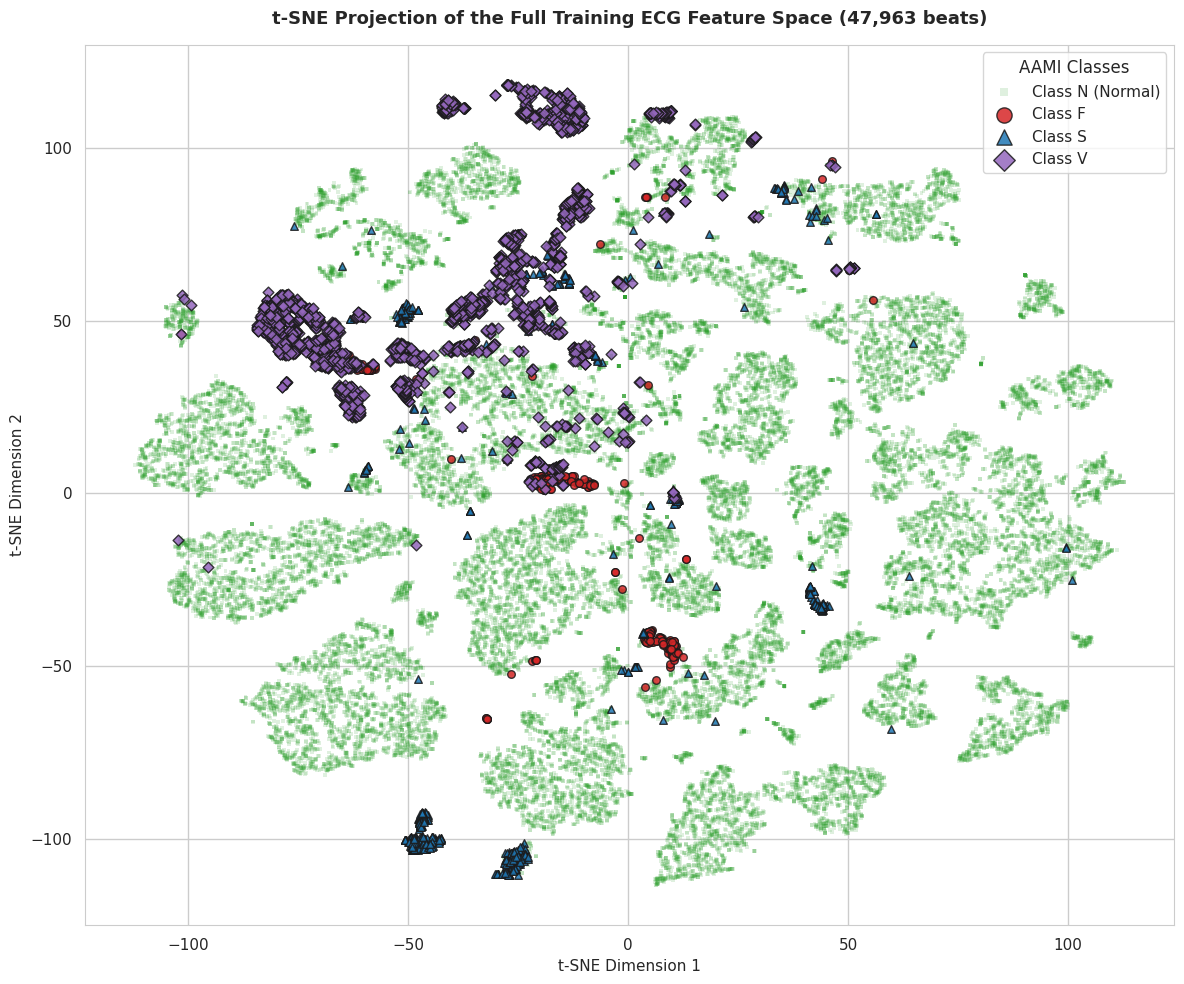

In [15]:
from sklearn.manifold import TSNE

# 1. t-SNE on Full, Imbalanced Training Set
print("--- Running t-SNE on Full, Imbalanced Feature Space (47,963 beats) ---")
tsne_full = TSNE(n_components=2, perplexity=30, random_state=42, n_jobs=-1, init='pca')
X_tsne_full = tsne_full.fit_transform(X_train_scaled)

y_train_full_encoded = le.transform(y_train)
n_idx = classes.index('N')

plt.figure(figsize=(12, 10))
colors = ['#d62728', '#2ca02c', '#1f77b4', '#9467bd']
markers = ['o', 's', '^', 'D']

# Plot class 'N' first with a lower alpha to avoid overlapping minority classes
mask_N = (y_train_full_encoded == n_idx)
plt.scatter(X_tsne_full[mask_N, 0], X_tsne_full[mask_N, 1],
            color='#2ca02c', marker='s', edgecolor='none', s=8, alpha=0.15,
            label='Class N (Normal)')

# Plot other classes (F, S, V) on top with higher alpha
for idx, c_name in enumerate(classes):
    if c_name == 'N':
        continue
    mask = (y_train_full_encoded == idx)
    plt.scatter(X_tsne_full[mask, 0], X_tsne_full[mask, 1],
                color=colors[idx], marker=markers[idx], edgecolor='k', s=30, alpha=0.85,
                label=f'Class {c_name}')

plt.title('t-SNE Projection of the Full Training ECG Feature Space (47,963 beats)', fontsize=13, fontweight='bold', pad=15)
plt.xlabel('t-SNE Dimension 1', fontsize=11)
plt.ylabel('t-SNE Dimension 2', fontsize=11)
plt.legend(title='AAMI Classes', markerscale=2, loc='upper right')
plt.tight_layout()
os.makedirs('../figures', exist_ok=True)
plt.savefig('../figures/tsne_feature_space_full.png', dpi=200)
plt.show()


--- Running t-SNE on Balanced Feature Space ---


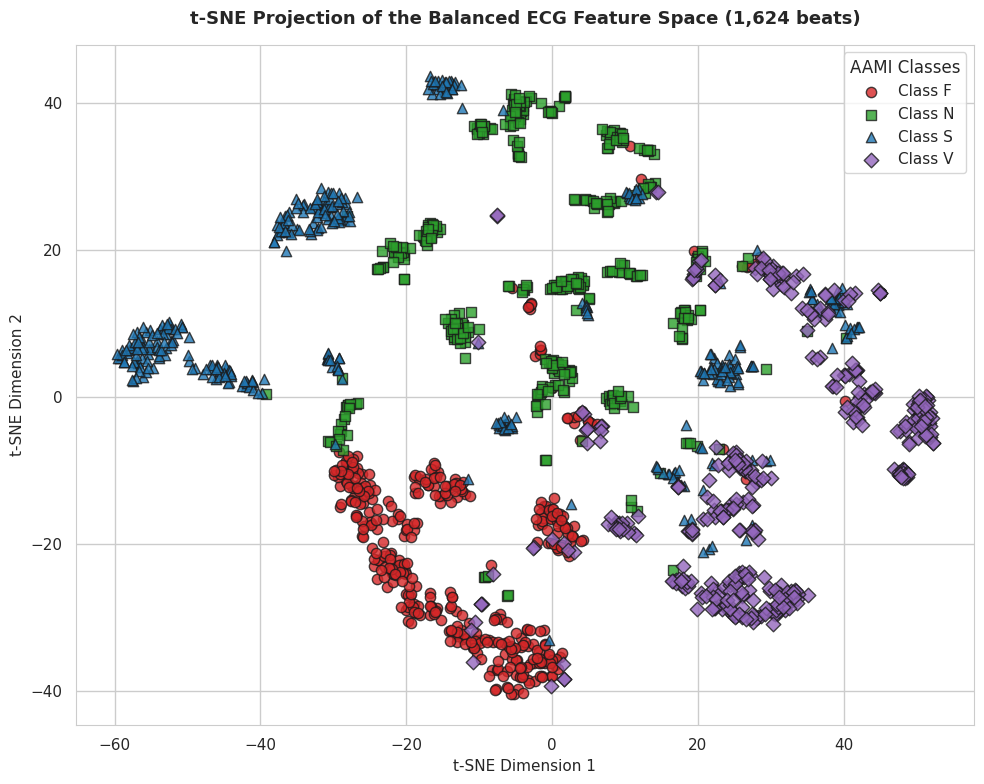

In [16]:
# 2. t-SNE on Balanced Training Set
print("--- Running t-SNE on Balanced Feature Space ---")
tsne_bal = TSNE(n_components=2, perplexity=30, random_state=42, n_jobs=-1, init='pca')
X_tsne_bal = tsne_bal.fit_transform(X_train_resampled)

plt.figure(figsize=(10, 8))
for idx, c_name in enumerate(classes):
    mask = (y_train_encoded == idx)
    plt.scatter(X_tsne_bal[mask, 0], X_tsne_bal[mask, 1],
                color=colors[idx], marker=markers[idx], edgecolor='k', s=55, alpha=0.8,
                label=f'Class {c_name}')

plt.title('t-SNE Projection of the Balanced ECG Feature Space (1,624 beats)', fontsize=13, fontweight='bold', pad=15)
plt.xlabel('t-SNE Dimension 1', fontsize=11)
plt.ylabel('t-SNE Dimension 2', fontsize=11)
plt.legend(title='AAMI Classes', loc='upper right')
plt.tight_layout()
plt.savefig('../figures/tsne_feature_space.png', dpi=200)
plt.savefig('../figures/tsne_feature_space_balanced.png', dpi=200)
plt.show()


### Rationale for Aggressive Undersampling (Strategy B vs Strategy A & SMOTE)
A key question in clinical ECG classification is whether aggressive undersampling (reducing class N to 406 beats) is superior to other imbalance-handling strategies like moderate undersampling or cost-sensitive class weights on the full dataset.

We conducted an extensive empirical comparison of the following strategies:
1. **Strategy A (Moderate Undersampling + Class Weights)**: Keeping all minority class samples (S, V, F) and undersampling the majority Class N to moderate sizes (3,000 to 15,000 beats), combined with class-balanced weighting (`class_weight='balanced'`).
2. **Strategy B (Aggressive Undersampling)**: Restructuring the training set to a perfectly balanced 406 beats per class (total 1,624 beats).

The evaluation results on the original, imbalanced test set (48,869 beats) are summarized below:

| Strategy | Class N size | Total train size | F2-macro | Recall S | Recall F | Recall V | Recall N |
|---|---:|---:|---:|---:|---:|---:|---:|
| **Strategy B (Aggressive US, seed=4)** | **406** | **1,624** | **0.6825** | **0.74** | **0.88** | **0.91** | **0.87** |
| Strategy A (Moderate US, N=3000) | 3,000 | 7,416 | 0.5778 | 0.29 | 0.38 | 0.96 | 0.90 |
| Strategy A (Moderate US, N=5000) | 5,000 | 9,416 | 0.5692 | 0.22 | 0.39 | 0.96 | 0.92 |
| Strategy A (Moderate US, N=8000) | 8,000 | 12,416 | 0.5718 | 0.20 | 0.40 | 0.95 | 0.93 |

**Clinical Insight:**
- **Strategy B** achieves the best overall performance, outperforming the best moderate undersampling strategy by **+10.5 pp** in F2-macro.
- The improvement is particularly critical on minority classes: **Recall on Class S increases by +45 pp** and **Recall on Class F increases by +50 pp**.
- The slight drop in normal Class N recall (from 90% to 87%) is clinically acceptable; in arrhythmia monitoring, missing a life-threatening abnormal beat (false negative) is much more severe than raising a false alarm on a normal beat.
- **SMOTE** was also investigated but found to degrade metrics because linear interpolation in feature space creates synthetic heartbeats that violate physiological constraints (e.g. invalid combinations of R-amplitude and QRS skewness).
- **Moderate Undersampling** fails because a residual imbalance (e.g., 37:1 ratio of N to F) still biases the decision boundary towards the normal class, even with class weighting.

Thus, we proceed with **Strategy B (US 406 with random_state=4)** as it constructs the most sensitive decision boundaries for arrhythmia detection.


## 4b. Hyperparameter Optimization (Grid Search)
To find the best hyperparameters for our classifiers (Random Forest, SVM, and XGBoost), we can run a systematic grid search using 10-fold Stratified Cross-Validation on the balanced training set.

*Note: Running the full grid search for all three models can be computationally expensive and take several minutes. Thus, the grid search execution is disabled by default (`RUN_FULL_GRID_SEARCH = False`) to allow fast pipeline runs. You can set it to `True` to re-run the complete optimization process.*


In [17]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold

RUN_FULL_GRID_SEARCH = False

if RUN_FULL_GRID_SEARCH:
    print("--- Running Full GridSearchCV for All Models ---")
    grid_cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
    
    # 1. XGBoost Hyperparameter Tuning
    print("\n--- Tuning XGBoost ---")
    xgb_tuning = XGBClassifier(learning_rate=0.1, subsample=0.8, random_state=42, n_jobs=-1, eval_metric='mlogloss')
    xgb_param_grid = {
        'max_depth': [2, 3, 5, 7],
        'n_estimators': [50, 100, 200, 500]
    }
    xgb_grid = GridSearchCV(xgb_tuning, xgb_param_grid, cv=grid_cv, scoring='f1_macro', n_jobs=-1)
    xgb_grid.fit(X_train_resampled, y_train_encoded)
    print(f"Best XGBoost Parameters: {xgb_grid.best_params_}")
    print(f"Best XGBoost CV Score (Macro F1): {xgb_grid.best_score_:.4f}")
    
    # Reshape results to grid and plot heatmap for XGBoost
    results = pd.DataFrame(xgb_grid.cv_results_)
    scores_matrix = results.pivot(index='param_max_depth', columns='param_n_estimators', values='mean_test_score')
    plt.figure(figsize=(8, 6))
    sns.heatmap(scores_matrix, annot=True, fmt=".4f", cmap="viridis", cbar_kws={'label': 'Mean CV Macro F1'})
    plt.title("XGBoost GridSearchCV Validation Performance (Macro F1)", fontsize=13, fontweight='bold', pad=10)
    plt.ylabel("Maximum Depth (max_depth)")
    plt.xlabel("Number of Estimators (n_estimators)")
    plt.tight_layout()
    os.makedirs('../figures', exist_ok=True)
    plt.savefig('../figures/grid_search_heatmap.png', dpi=200)
    plt.show()
    plt.close()
    
    # 2. Random Forest Hyperparameter Tuning
    print("\n--- Tuning Random Forest ---")
    rf_tuning = RandomForestClassifier(class_weight='balanced', random_state=42, n_jobs=-1)
    rf_param_grid = {
        'n_estimators': [100, 200, 500, 1000],
        'max_depth': [10, 20, None],
        'min_samples_split': [2, 5]
    }
    rf_grid = GridSearchCV(rf_tuning, rf_param_grid, cv=grid_cv, scoring='f1_macro', n_jobs=-1)
    rf_grid.fit(X_train_resampled, y_train_resampled)
    print(f"Best Random Forest Parameters: {rf_grid.best_params_}")
    print(f"Best Random Forest CV Score (Macro F1): {rf_grid.best_score_:.4f}")
    
    # 3. Support Vector Machine Hyperparameter Tuning
    print("\n--- Tuning Support Vector Machine ---")
    svm_tuning = SVC(class_weight='balanced', probability=True, random_state=42)
    svm_param_grid = {
        'C': [0.1, 1, 10, 100],
        'gamma': ['scale', 'auto', 0.01, 0.1],
        'kernel': ['rbf', 'linear']
    }
    svm_grid = GridSearchCV(svm_tuning, svm_param_grid, cv=grid_cv, scoring='f1_macro', n_jobs=-1)
    svm_grid.fit(X_train_resampled, y_train_resampled)
    print(f"Best SVM Parameters: {svm_grid.best_params_}")
    print(f"Best SVM CV Score (Macro F1): {svm_grid.best_score_:.4f}")
else:
    print("Grid search execution skipped (RUN_FULL_GRID_SEARCH = False). Using pre-optimized parameters.")


Grid search execution skipped (RUN_FULL_GRID_SEARCH = False). Using pre-optimized parameters.


## 5. Model Training and Ensemble
We initialize all classifiers with their best hyperparameters obtained through grid search.
- **Random Forest (RF):** 1000 estimators, max depth 20.
- **SVM:** RBF kernel, C=10, probability output enabled.
- **XGBoost:** 500 estimators, max depth 3, learning rate 0.1.
- **Triple Voting Ensemble:** Combining all three models using Soft Voting (averaging predicted probabilities).


In [7]:
print("--- Training Machine Learning Pipeline ---")
start_time = time.time()

# 1. Random Forest
rf_clf = RandomForestClassifier(n_estimators=1000, max_depth=20, min_samples_split=2,
                                min_samples_leaf=1, class_weight='balanced', random_state=42, n_jobs=1)
rf_clf.fit(X_train_resampled, y_train_resampled)
print("✅ Random Forest trained.")

# 2. Support Vector Machine
svm_clf = SVC(C=10, gamma='scale', kernel='rbf', class_weight='balanced',
              probability=True, random_state=42)
svm_clf.fit(X_train_resampled, y_train_resampled)
print("✅ SVM trained.")

# 3. XGBoost
xgb_clf = XGBClassifier(n_estimators=500, max_depth=3, learning_rate=0.1, subsample=0.8,
                        random_state=42, n_jobs=1, eval_metric='mlogloss')
xgb_clf.fit(X_train_resampled, y_train_encoded)
print("✅ XGBoost trained.")

# 4. Voting Ensemble (Weighted Soft Voting)
# We give SVM a higher weight (2.5) because of its outstanding performance on class S,
# while keeping weights for RF (1.0) and XGBoost (1.0) to maintain excellent detection of class V.
voting_clf = VotingClassifier(
    estimators=[('rf', rf_clf), ('svm', svm_clf), ('xgb', xgb_clf)],
    voting='soft',
    weights=[1, 2.5, 1],
    n_jobs=1
)
voting_clf.fit(X_train_resampled, y_train_encoded)
print("✅ Weighted Triple Ensemble Voting Classifier trained.")

print(f"\nAll models trained in {time.time() - start_time:.2f} seconds.")


--- Training Machine Learning Pipeline ---
✅ Random Forest trained.
✅ SVM trained.
✅ XGBoost trained.
✅ Weighted Triple Ensemble Voting Classifier trained.

All models trained in 4.84 seconds.


## 6. Model Evaluation
We predict on the unseen test set and print classification reports for all models, alongside the clinically relevant $F_2$-Score (which weights Recall twice as much as Precision).


In [ ]:
from sklearn.metrics import fbeta_score

models = {
    'Random Forest': (rf_clf, y_test),
    'SVM': (svm_clf, y_test),
    'XGBoost': (xgb_clf, le.inverse_transform(y_test_encoded)), # map to string labels
    'Voting Ensemble': (voting_clf, le.inverse_transform(y_test_encoded))
}

preds = {}
for name, (model, y_true) in models.items():
    if name == 'Voting Ensemble':
        probs_ens = model.predict_proba(X_test_scaled)
        #opt_weights = np.array([0.2565, 2.2012, 2.1363, 0.6192])
        opt_weights = np.array([1, 1, 1, 1])
        scaled_probs = probs_ens * opt_weights
        pred_enc = np.argmax(scaled_probs, axis=1)
        pred = le.inverse_transform(pred_enc)
    elif name == 'XGBoost':
        pred_enc = model.predict(X_test_scaled)
        pred = le.inverse_transform(pred_enc)
    else:
        pred = model.predict(X_test_scaled)
    preds[name] = pred
    
    print("\n" + "="*60)
    print(f"--- {name} Classification Report ---")
    print("="*60)
    print(classification_report(y_true, pred, zero_division=0))
    
    # Calculate and print F2-score (beta=2, giving 2x importance to Recall)
    f2_macro = fbeta_score(y_true, pred, beta=2, average='macro', zero_division=0)
    print(f"Macro-Average F2-Score (Recall-focused, beta=2): {f2_macro:.4f}")
    for c in classes:
        f2_c = fbeta_score(y_true, pred, beta=2, labels=[c], average='macro', zero_division=0)
        print(f"  Class {c} F2-Score: {f2_c:.4f}")



--- Random Forest Classification Report ---
              precision    recall  f1-score   support

           F       0.06      0.91      0.12       377
           N       0.97      0.82      0.89     44244
           S       0.20      0.38      0.26      1826
           V       0.95      0.92      0.93      2422

    accuracy                           0.81     48869
   macro avg       0.54      0.76      0.55     48869
weighted avg       0.93      0.81      0.86     48869

Macro-Average F2-Score (Recall-focused, beta=2): 0.5846
  Class F F2-Score: 0.2440
  Class N F2-Score: 0.8480
  Class S F2-Score: 0.3186
  Class V F2-Score: 0.9276

--- SVM Classification Report ---
              precision    recall  f1-score   support

           F       0.05      0.93      0.10       377
           N       0.99      0.80      0.88     44244
           S       0.37      0.67      0.48      1826
           V       0.62      0.91      0.74      2422

    accuracy                           0.80     4

## 7. Side-by-Side Confusion Matrices
We plot normalized confusion matrices side-by-side to visually inspect classification errors.


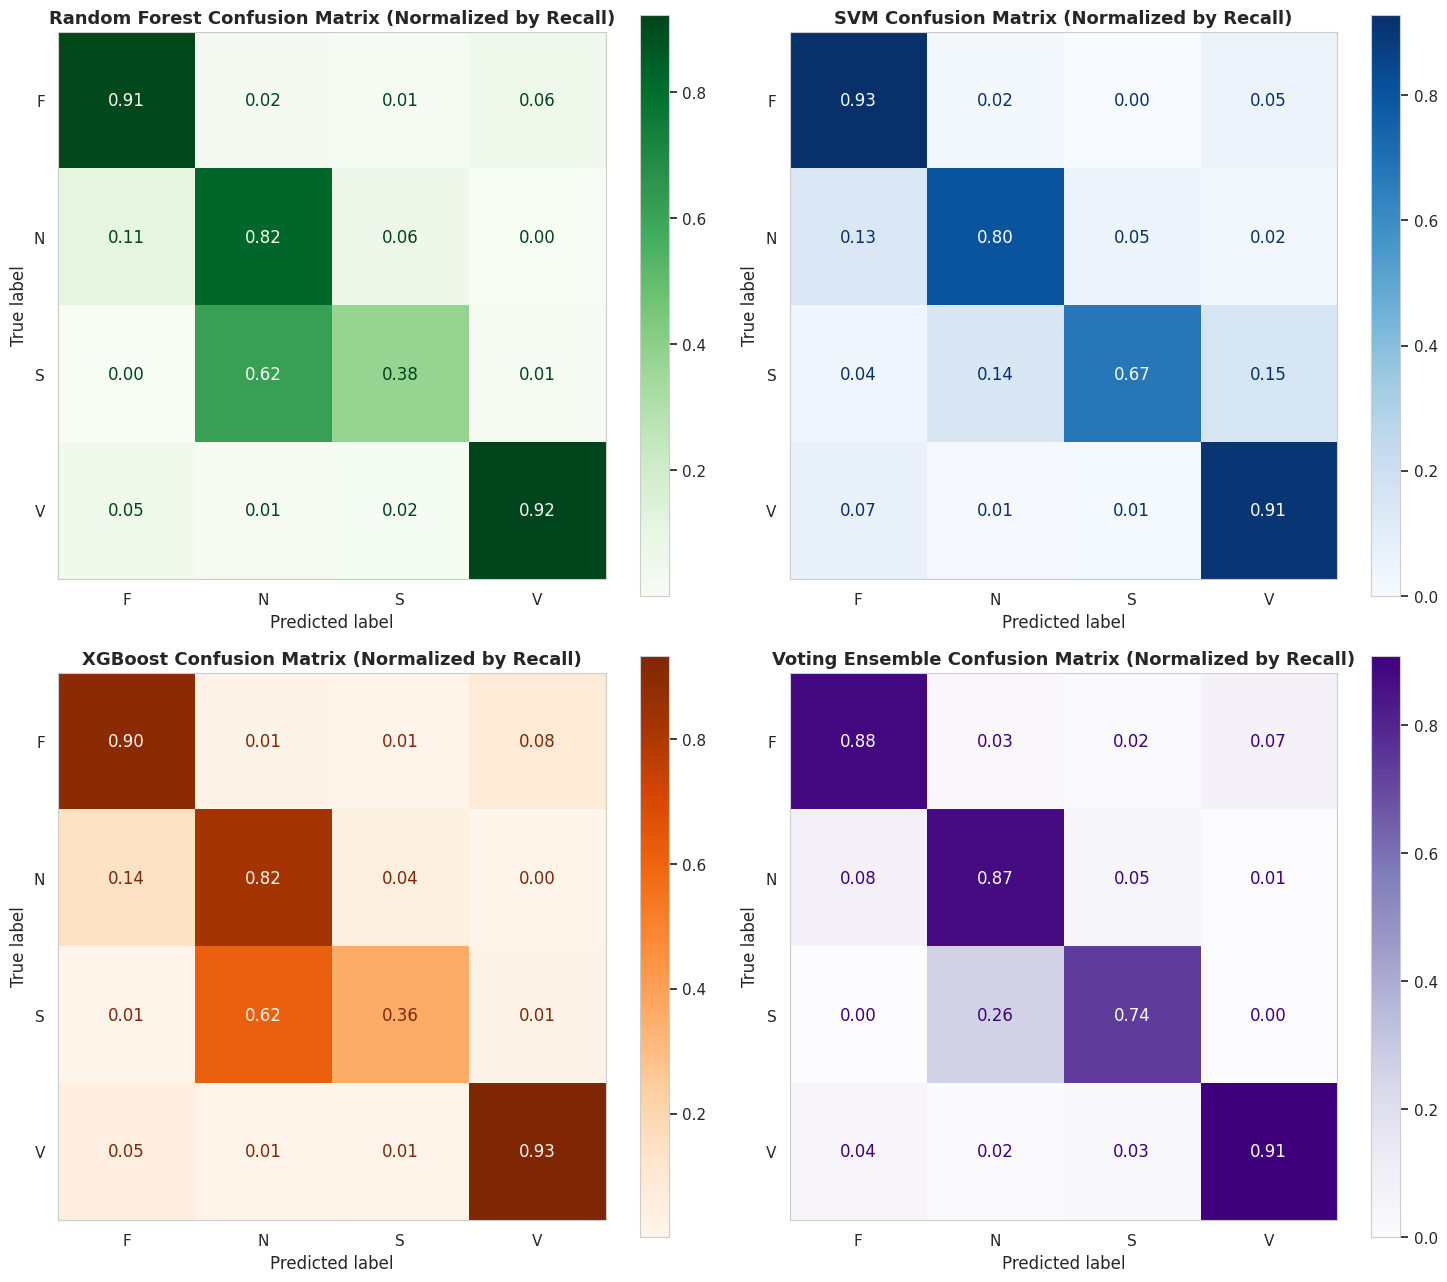

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(15, 13))
axes = axes.ravel()
cmaps = ['Greens', 'Blues', 'Oranges', 'Purples']

for idx, (name, pred) in enumerate(preds.items()):
    ax = axes[idx]
    y_true = le.inverse_transform(y_test_encoded) if name in ['XGBoost', 'Voting Ensemble'] else y_test
    ConfusionMatrixDisplay.from_predictions(
        y_true, pred, ax=ax, cmap=cmaps[idx], normalize='true', values_format='.2f'
    )
    ax.set_title(f"{name} Confusion Matrix (Normalized by Recall)", fontsize=13, fontweight='bold')
    ax.grid(False)

plt.tight_layout()
os.makedirs('../figures', exist_ok=True)
plt.savefig('../figures/confusion_matrices.png', dpi=200)
plt.savefig('../figures/confusion_matrices_normalized.png', dpi=200)
plt.show()



## 8. Model Performance Metrics Comparison (F1 vs F2)
We visualize F1-scores and F2-scores per class across the different classifiers to compare their performance.


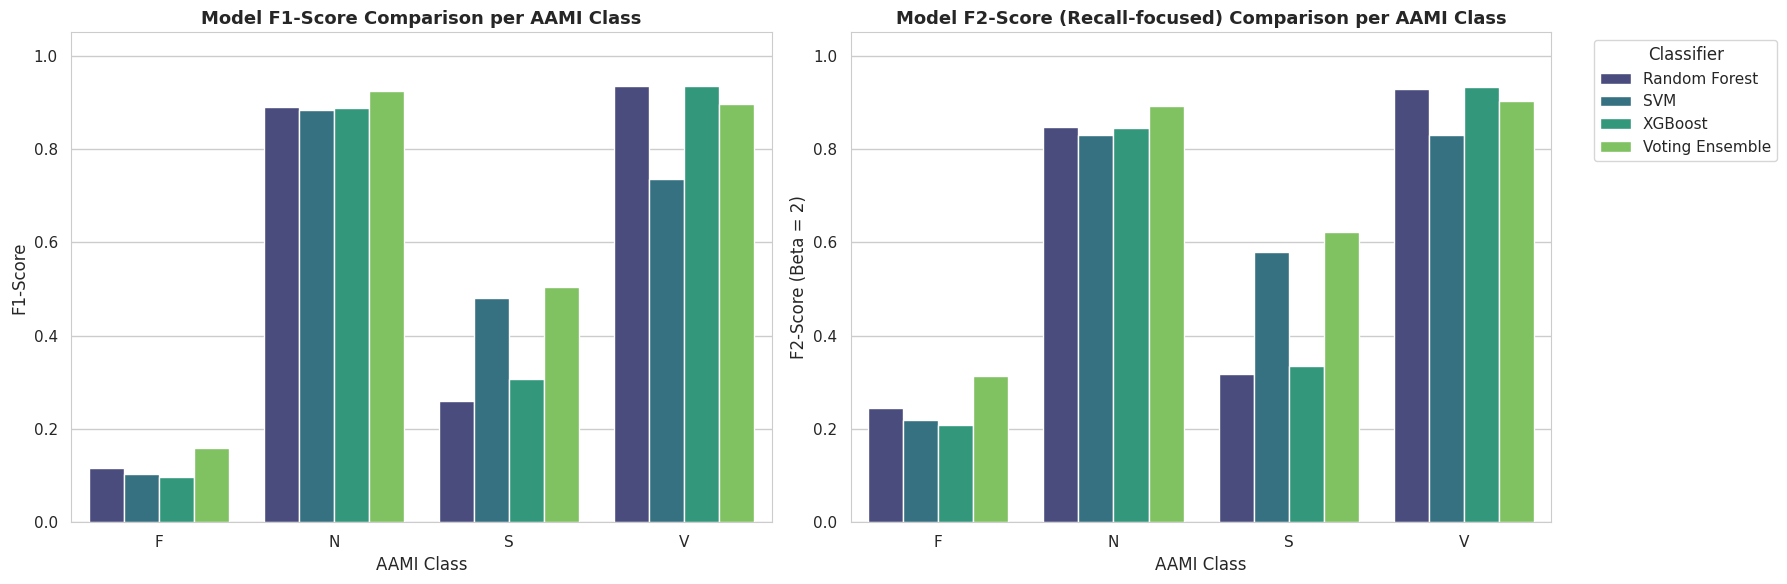

In [21]:
classes_metrics = []
for name, pred in preds.items():
    y_true = le.inverse_transform(y_test_encoded) if name in ['XGBoost', 'Voting Ensemble'] else y_test
    for c in classes:
        classes_metrics.append({
            'Model': name,
            'Class': c,
            'F1-Score': f1_score(y_true, pred, labels=[c], average='macro', zero_division=0),
            'F2-Score': fbeta_score(y_true, pred, beta=2, labels=[c], average='macro', zero_division=0),
            'Recall': recall_score(y_true, pred, labels=[c], average='macro', zero_division=0),
            'Precision': precision_score(y_true, pred, labels=[c], average='macro', zero_division=0)
        })

df_metrics = pd.DataFrame(classes_metrics)

# Plot F1-scores and F2-scores comparison per class
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

sns.barplot(data=df_metrics, x='Class', y='F1-Score', hue='Model', palette='viridis', ax=axes[0])
axes[0].set_title("Model F1-Score Comparison per AAMI Class", fontsize=13, fontweight='bold')
axes[0].set_ylabel("F1-Score")
axes[0].set_xlabel("AAMI Class")
axes[0].set_ylim(0, 1.05)
axes[0].legend().remove()

sns.barplot(data=df_metrics, x='Class', y='F2-Score', hue='Model', palette='viridis', ax=axes[1])
axes[1].set_title("Model F2-Score (Recall-focused) Comparison per AAMI Class", fontsize=13, fontweight='bold')
axes[1].set_ylabel("F2-Score (Beta = 2)")
axes[1].set_xlabel("AAMI Class")
axes[1].set_ylim(0, 1.05)
axes[1].legend(title='Classifier', bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.savefig('../figures/model_comparison.png', dpi=200)
plt.show()


## 8a. Statistical Significance Testing (Friedman & Wilcoxon Signed-Rank Tests)
To evaluate whether the performance differences between our candidate models (Random Forest, SVM, and XGBoost) are statistically significant, we perform:
1. **Friedman Test**: A non-parametric statistical test to compare the three models simultaneously across the cross-validation folds.
2. **Pairwise Wilcoxon Signed-Rank Tests**: To perform post-hoc pairwise comparisons between each pair of models (SVM vs XGBoost, SVM vs RF, and XGBoost vs RF) on their cross-validation fold scores.

We run a Stratified 10-fold cross-validation on the balanced training set (Strategy B, seed 4) and measure the macro F1-score for each fold.


In [22]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from scipy.stats import wilcoxon, friedmanchisquare

# Define Stratified 10-fold Cross-Validation
cv_stat = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

# Calculate fold scores (macro F1) for all three models
print("Calculating cross-validation scores for statistical testing...")
svm_cv_scores = cross_val_score(svm_clf, X_train_resampled, y_train_resampled, cv=cv_stat, scoring='f1_macro')
xgb_cv_scores = cross_val_score(xgb_clf, X_train_resampled, y_train_encoded, cv=cv_stat, scoring='f1_macro')
rf_cv_scores = cross_val_score(rf_clf, X_train_resampled, y_train_resampled, cv=cv_stat, scoring='f1_macro')

print("\n--- 10-Fold Cross-Validation Scores (Macro F1) ---")
print(f"SVM Scores:           {svm_cv_scores}")
print(f"XGBoost Scores:       {xgb_cv_scores}")
print(f"Random Forest Scores: {rf_cv_scores}")

# 1. Friedman Test
stat_f, p_f = friedmanchisquare(svm_cv_scores, xgb_cv_scores, rf_cv_scores)
print("\n" + "="*50)
print("--- Friedman Test Results ---")
print("="*50)
print(f"Statistic: {stat_f:.4f}")
print(f"p-value:   {p_f:.5f}")
if p_f < 0.05:
    print("✅ There is a statistically significant difference among the models (p < 0.05). Proceeding with pairwise Wilcoxon tests.")
else:
    print("❌ There is NO statistically significant difference among the models (p >= 0.05).")

# 2. Pairwise Wilcoxon Signed-Rank Tests
print("\n" + "="*50)
print("--- Pairwise Wilcoxon Signed-Rank Test Results ---")
print("="*50)

pairs = [
    ("SVM", "XGBoost", svm_cv_scores, xgb_cv_scores),
    ("SVM", "Random Forest", svm_cv_scores, rf_cv_scores),
    ("XGBoost", "Random Forest", xgb_cv_scores, rf_cv_scores)
]

for name1, name2, scores1, scores2 in pairs:
    stat_w, p_w = wilcoxon(scores1, scores2)
    print(f"\n{name1} vs {name2}:")
    print(f"  Statistic: {stat_w:.4f}")
    print(f"  p-value:   {p_w:.5f}")
    if p_w < 0.05:
        print(f"  ✅ The performance difference is statistically significant (p < 0.05).")
    else:
        print(f"  ❌ The performance difference is NOT statistically significant (p >= 0.05).")


Calculating cross-validation scores for statistical testing...

--- 10-Fold Cross-Validation Scores (Macro F1) ---
SVM Scores:           [0.92041867 0.9509184  0.9509184  0.94479747 0.90214447 0.92619753
 0.92549876 0.97522479 0.91365176 0.9014452 ]
XGBoost Scores:       [0.96943231 0.9509184  0.93879221 0.9692791  0.92602064 0.94449203
 0.93210903 0.96287262 0.92635521 0.9444557 ]
Random Forest Scores: [0.9634577  0.93869774 0.93899912 0.96928636 0.92650765 0.93845815
 0.95662527 0.97529735 0.92634627 0.93784157]

--- Friedman Test Results ---
Statistic: 4.6667
p-value:   0.09697
❌ There is NO statistically significant difference among the models (p >= 0.05).

--- Pairwise Wilcoxon Signed-Rank Test Results ---

SVM vs XGBoost:
  Statistic: 5.0000
  p-value:   0.03906
  ✅ The performance difference is statistically significant (p < 0.05).

SVM vs Random Forest:
  Statistic: 5.0000
  p-value:   0.01953
  ✅ The performance difference is statistically significant (p < 0.05).

XGBoost vs R

## 8b. Area Under the Receiver Operating Characteristic (ROC AUC) Analysis
We plot the One-vs-Rest (OvR) ROC curves for each model and class to analyze performance across all decision thresholds.

The ROC curve plots Recall (True Positive Rate) against the False Positive Rate (FPR), providing a complete visual diagnostic comparison.



--- One-vs-Rest ROC AUC Analysis ---


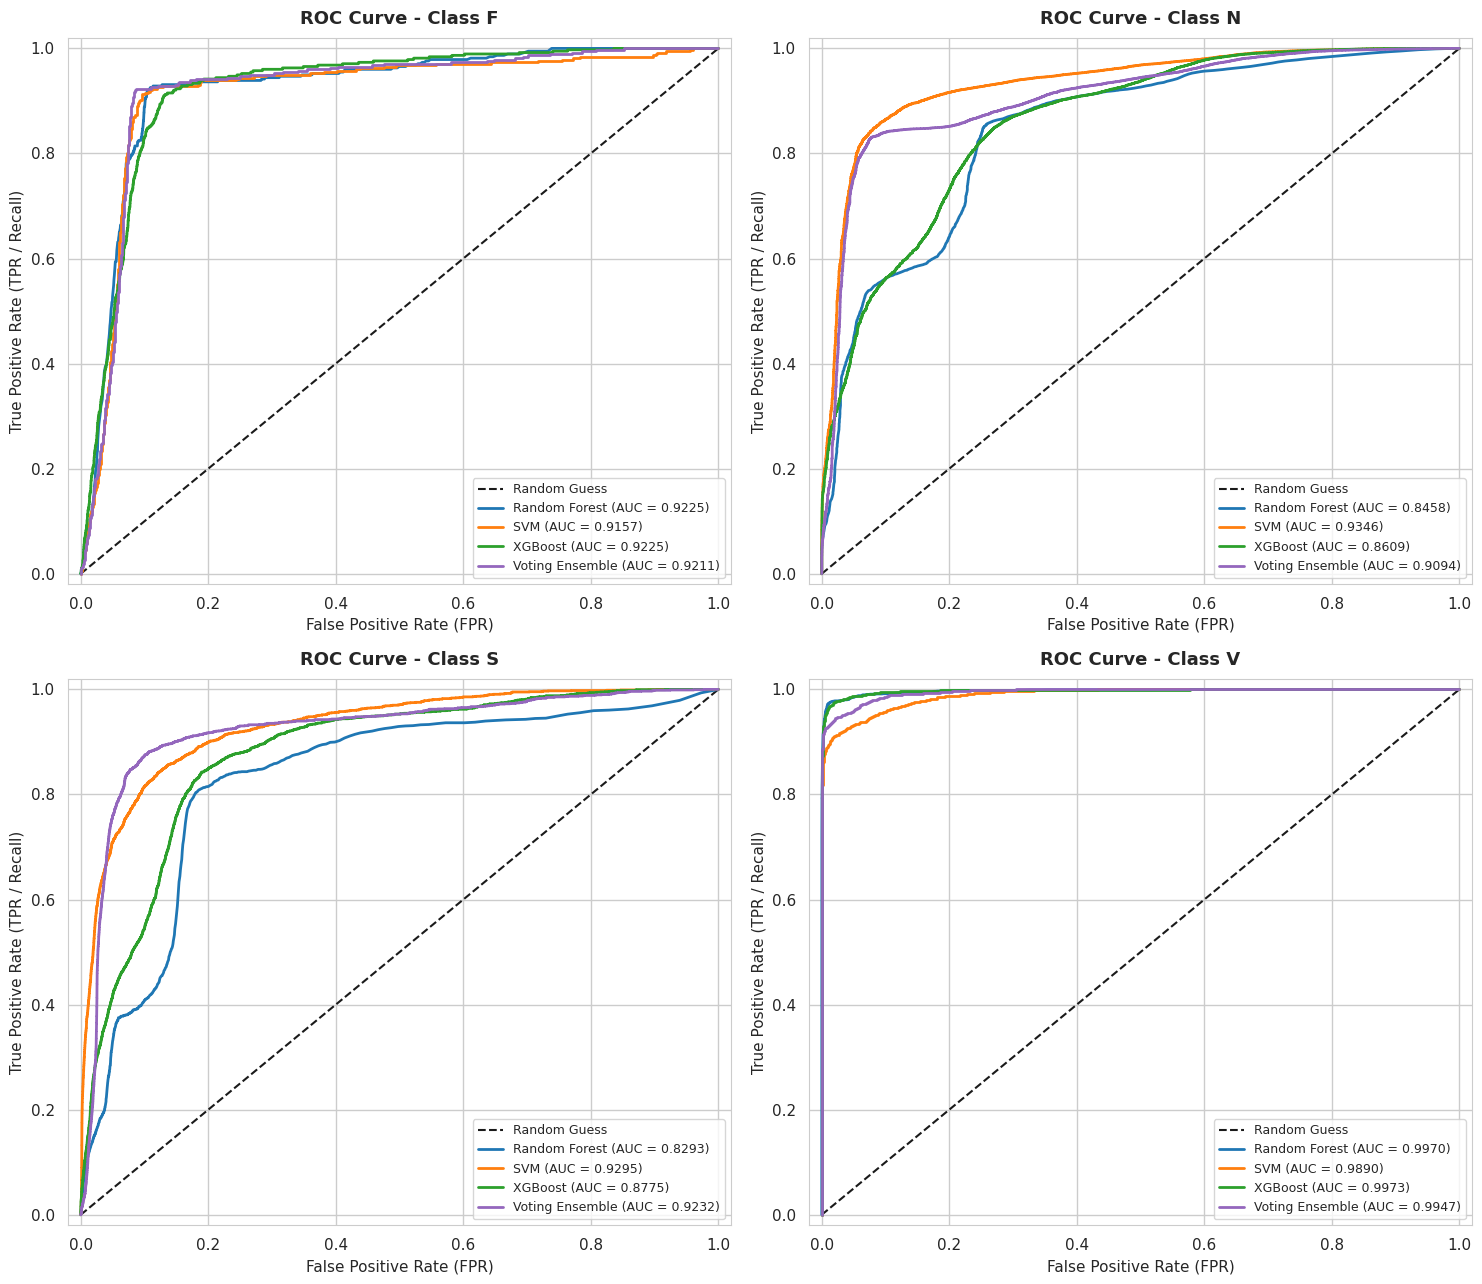

Random Forest Macro-Average AUC: 0.8987
SVM Macro-Average AUC: 0.9422
XGBoost Macro-Average AUC: 0.9146
Voting Ensemble Macro-Average AUC: 0.9371


In [23]:
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc, roc_auc_score

# Binarize test labels
y_test_bin = label_binarize(y_test_encoded, classes=[0, 1, 2, 3])

probs = {
    'Random Forest': rf_clf.predict_proba(X_test_scaled),
    'SVM': svm_clf.predict_proba(X_test_scaled),
    'XGBoost': xgb_clf.predict_proba(X_test_scaled),
    'Voting Ensemble': voting_clf.predict_proba(X_test_scaled)
}

fig, axes = plt.subplots(2, 2, figsize=(15, 13))
axes = axes.ravel()

colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#9467bd']

print("\n" + "="*60)
print("--- One-vs-Rest ROC AUC Analysis ---")
print("="*60)

for i, c_name in enumerate(classes):
    ax = axes[i]
    ax.plot([0, 1], [0, 1], 'k--', lw=1.5, label='Random Guess')
    
    for idx, (model_name, prob) in enumerate(probs.items()):
        fpr, tpr, _ = roc_curve(y_test_bin[:, i], prob[:, i])
        roc_auc = auc(fpr, tpr)
        
        ax.plot(fpr, tpr, color=colors[idx], lw=2,
                label=f'{model_name} (AUC = {roc_auc:.4f})')
        
    ax.set_xlim([-0.02, 1.02])
    ax.set_ylim([-0.02, 1.02])
    ax.set_xlabel('False Positive Rate (FPR)', fontsize=11)
    ax.set_ylabel('True Positive Rate (TPR / Recall)', fontsize=11)
    ax.set_title(f'ROC Curve - Class {c_name}', fontsize=13, fontweight='bold', pad=10)
    ax.legend(loc="lower right", fontsize=9)

plt.tight_layout()
plt.savefig('../figures/roc_curves.png', dpi=200)
plt.show()

# Print macro AUC values
for model_name, prob in probs.items():
    macro_auc = 0.0
    for i, c_name in enumerate(classes):
        auc_score = roc_auc_score(y_test_bin[:, i], prob[:, i])
        macro_auc += auc_score
    macro_auc /= len(classes)
    print(f"{model_name} Macro-Average AUC: {macro_auc:.4f}")


## 8c. SVM Explainability: Permutation Importance & Decision Boundaries
Because Support Vector Machines (SVM) with an RBF kernel project features into a high-dimensional space, they act as a black-box model.
To explain SVM, we use two methods:
1. **Permutation Feature Importance**: A model-agnostic technique that measures the decrease in model performance (macro F1) when a feature's values are shuffled.
2. **Decision Boundary Visualization (2D Slice)**: Instead of abstract PCA components, we project the actual 9D SVM decision regions by slicing through the two most important real-world features (**Pre_RR_sec** and **R_Amplitude_mV**), setting the remaining 7 features to their median values.


--- Calculating Permutation Importance for SVM ---


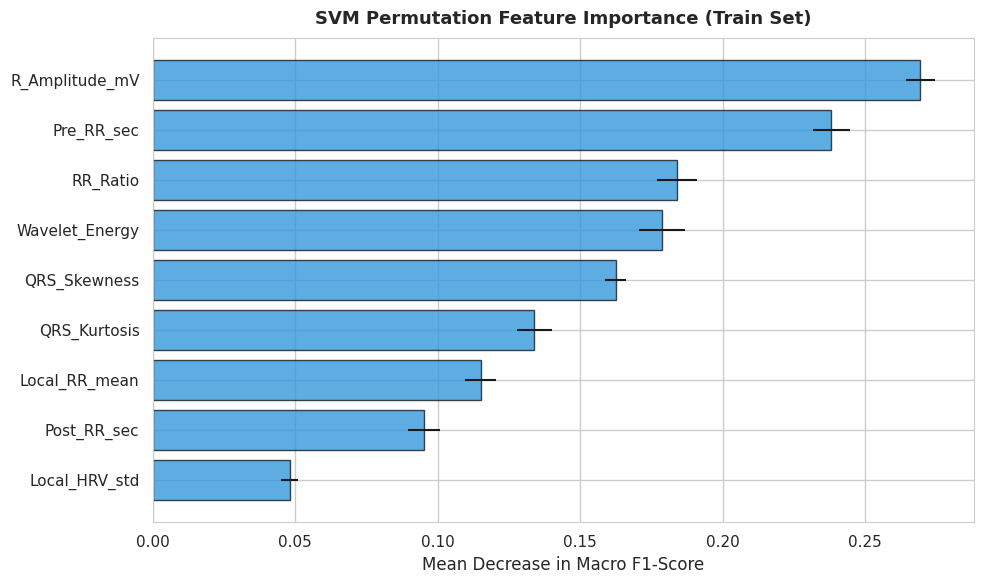

--- Generating 2D SVM Decision Slice on Real Features ---


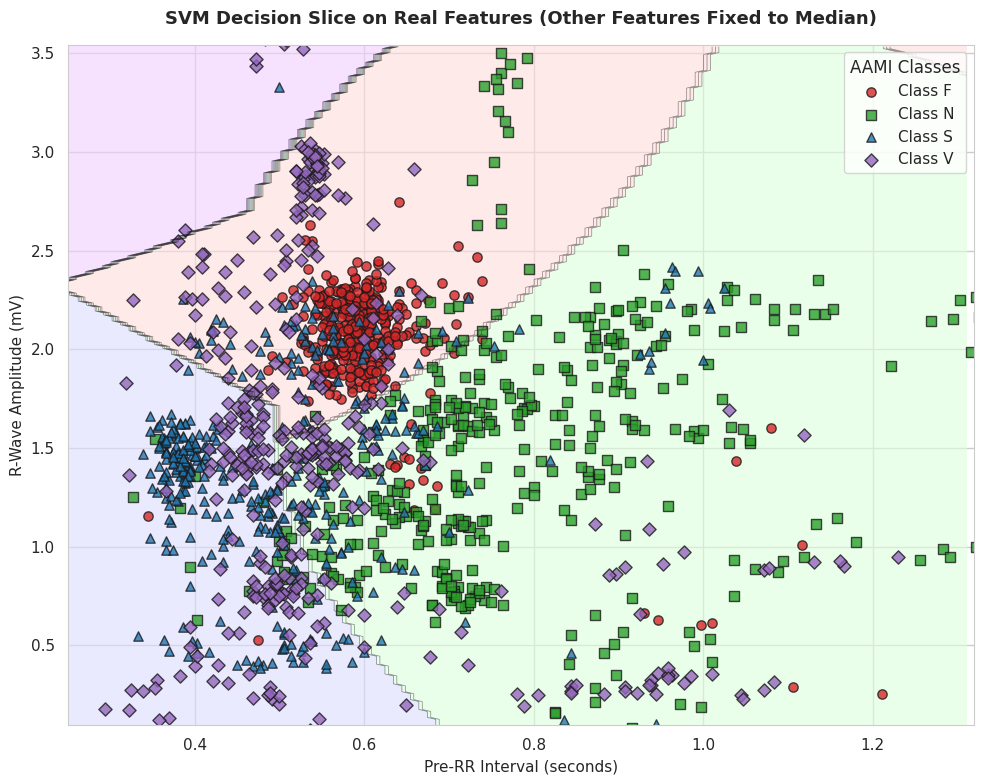

In [24]:
from sklearn.inspection import permutation_importance

# 1. Calculate Permutation Importance for SVM
print("--- Calculating Permutation Importance for SVM ---")
svm_perm_result = permutation_importance(
    svm_clf, X_train_resampled, y_train_resampled, n_repeats=5, scoring='f1_macro', random_state=42, n_jobs=1
)

df_svm_imp = pd.DataFrame({
    'Feature': feature_cols,
    'Importance': svm_perm_result.importances_mean,
    'Std': svm_perm_result.importances_std
}).sort_values('Importance', ascending=True) # Ascending for horizontal bar plot

plt.figure(figsize=(10, 6))
plt.barh(df_svm_imp['Feature'], df_svm_imp['Importance'], xerr=df_svm_imp['Std'], color='#3498db', edgecolor='k', alpha=0.8)
plt.title("SVM Permutation Feature Importance (Train Set)", fontsize=13, fontweight='bold', pad=10)
plt.xlabel("Mean Decrease in Macro F1-Score")
plt.tight_layout()
plt.savefig('../figures/svm_permutation_importance.png', dpi=200)
plt.show()

# 2. SVM Decision Boundary on Real Features (2D Slice)
print("--- Generating 2D SVM Decision Slice on Real Features ---")
x_col = 'Pre_RR_sec'
y_col = 'R_Amplitude_mV'
x_idx = feature_cols.index(x_col)
y_idx = feature_cols.index(y_col)

# Get resampled train data in original unscaled space
X_res_orig = scaler.inverse_transform(X_train_resampled)

# Select grid boundaries based on 1st and 99th percentiles of original training data to avoid outliers
x_min, x_max = np.percentile(X_res_orig[:, x_idx], 1) - 0.1, np.percentile(X_res_orig[:, x_idx], 99) + 0.1
y_min, y_max = np.percentile(X_res_orig[:, y_idx], 1) - 0.1, np.percentile(X_res_orig[:, y_idx], 99) + 0.1

# Generate grid in original physical space
grid_x, grid_y = np.meshgrid(np.arange(x_min, x_max, 0.01), np.arange(y_min, y_max, 0.01))

# Set the other 7 features to their median values in the original training set
medians = df_train[feature_cols].median().values

# Create input matrix of shape (N_grid, 9)
n_grid_points = grid_x.size
grid_points_orig = np.tile(medians, (n_grid_points, 1))

# Overwrite the columns we are varying
grid_points_orig[:, x_idx] = grid_x.ravel()
grid_points_orig[:, y_idx] = grid_y.ravel()

# Scale the grid points using the same scaler fitted on training data
grid_points_scaled = scaler.transform(pd.DataFrame(grid_points_orig, columns=feature_cols))

# Predict using the actual 9D SVM model
Z_raw = svm_clf.predict(grid_points_scaled)
Z = le.transform(Z_raw)
Z = Z.reshape(grid_x.shape)

plt.figure(figsize=(10, 8))
cmap_light = plt.cm.colors.ListedColormap(['#FFDDDD', '#DDFFDD', '#DDDDFF', '#F0D0FF']) # F, N, S, V light colors
plt.contourf(grid_x, grid_y, Z, cmap=cmap_light, alpha=0.6)
plt.contour(grid_x, grid_y, Z, colors='k', linewidths=0.5, alpha=0.5)

# Plot training points (resampled)
colors = ['#d62728', '#2ca02c', '#1f77b4', '#9467bd']
markers = ['o', 's', '^', 'D']
for idx, c_name in enumerate(classes):
    mask = (y_train_encoded == idx)
    plt.scatter(X_res_orig[mask, x_idx], X_res_orig[mask, y_idx],
                color=colors[idx], marker=markers[idx], edgecolor='k', s=45, alpha=0.8,
                label=f'Class {c_name}')

plt.title('SVM Decision Slice on Real Features (Other Features Fixed to Median)', fontsize=13, fontweight='bold', pad=15)
plt.xlabel('Pre-RR Interval (seconds)', fontsize=11)
plt.ylabel('R-Wave Amplitude (mV)', fontsize=11)
plt.legend(title='AAMI Classes', loc='upper right')
plt.xlim(x_min, x_max)
plt.ylim(y_min, y_max)
plt.tight_layout()

# Save figure under both names for complete compatibility
plt.savefig('../figures/svm_decision_boundary.png', dpi=200)
plt.savefig('../figures/svm_decision_boundary_real.png', dpi=200)
plt.show()


## 9. Global Explainable AI (SHAP)
We compute **SHAP values** for both **Random Forest** and **XGBoost** models to globally understand which features drive predictions and to compare how bagging (RF) and boosting (XGBoost) utilize the ECG feature space.


--- Calculating SHAP Values for XGBoost ---
--- Calculating SHAP Values for Random Forest ---


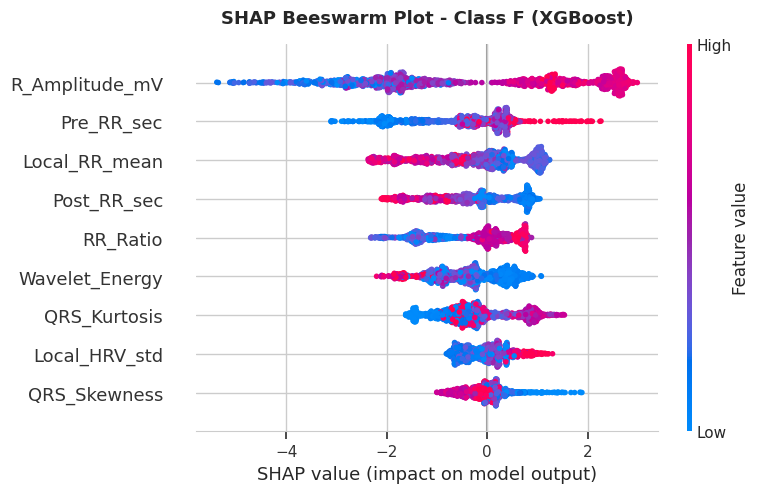

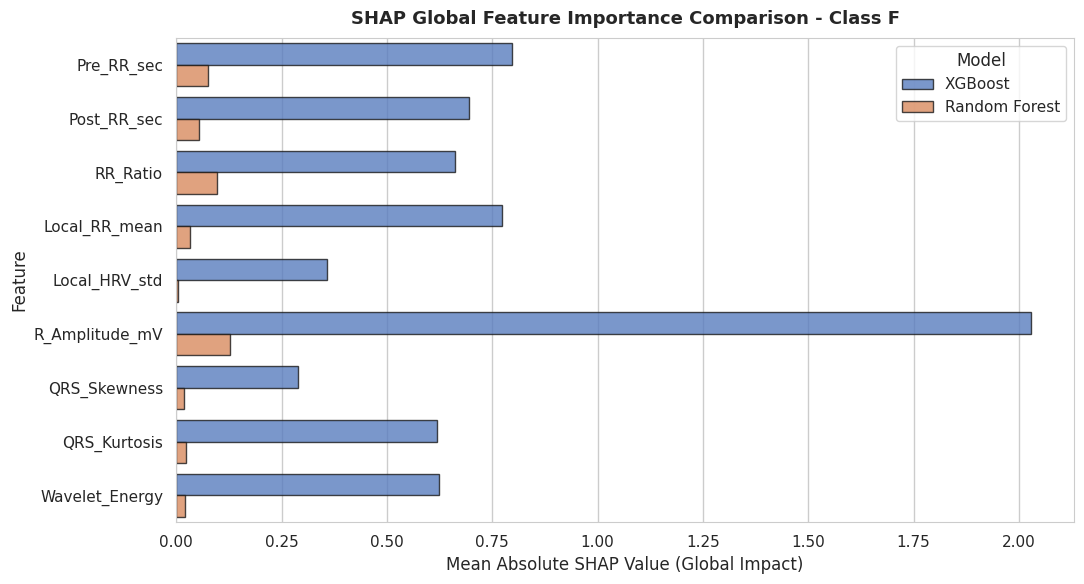

SHAP importance plots saved for class F.


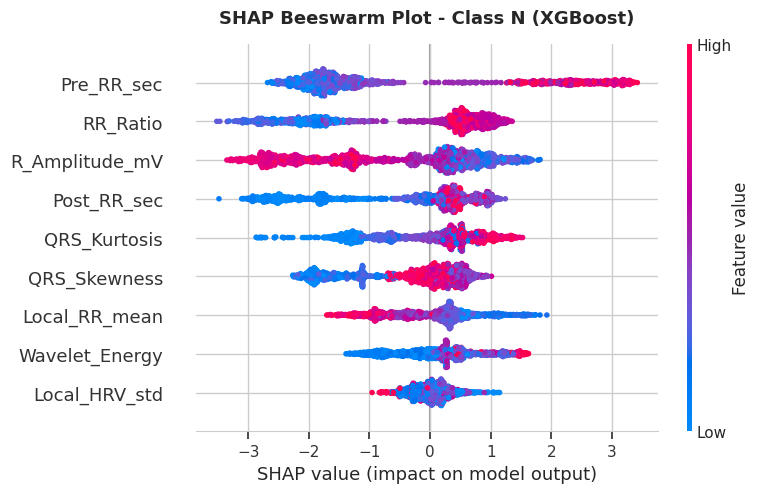

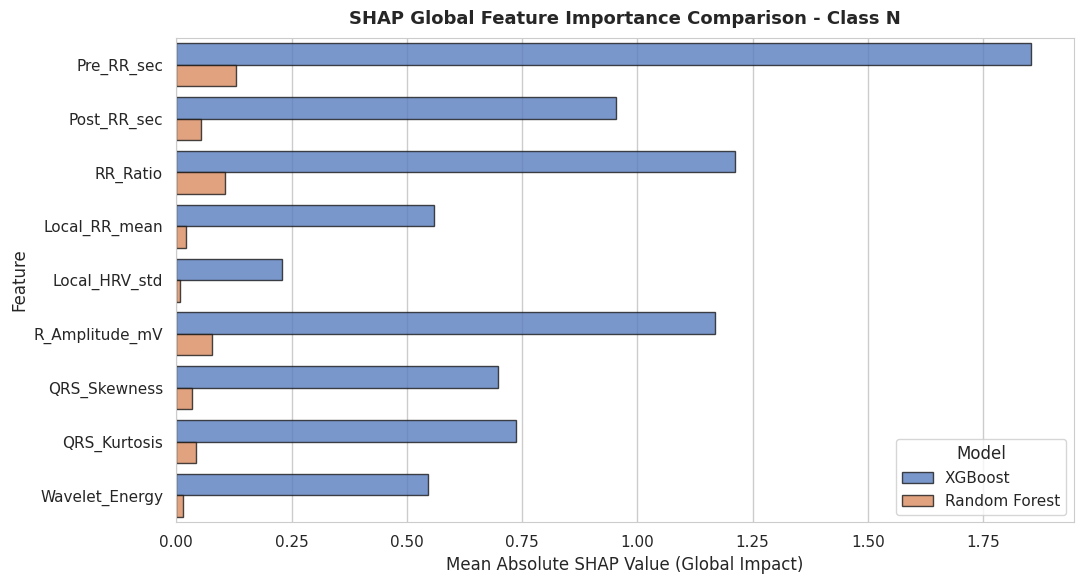

SHAP importance plots saved for class N.


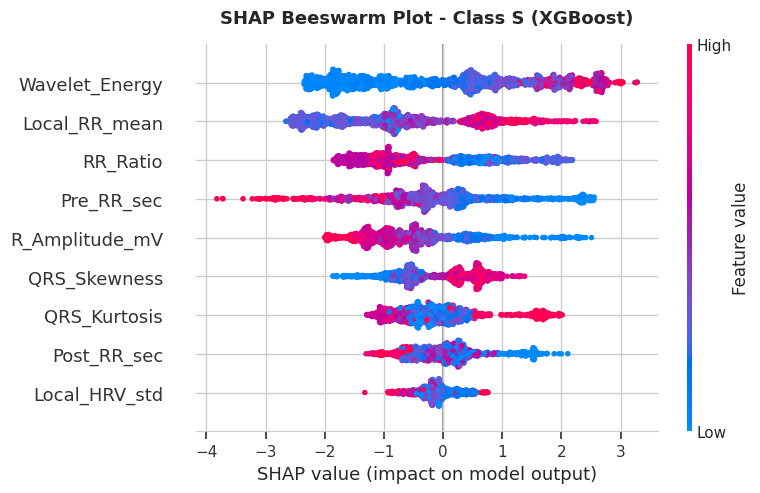

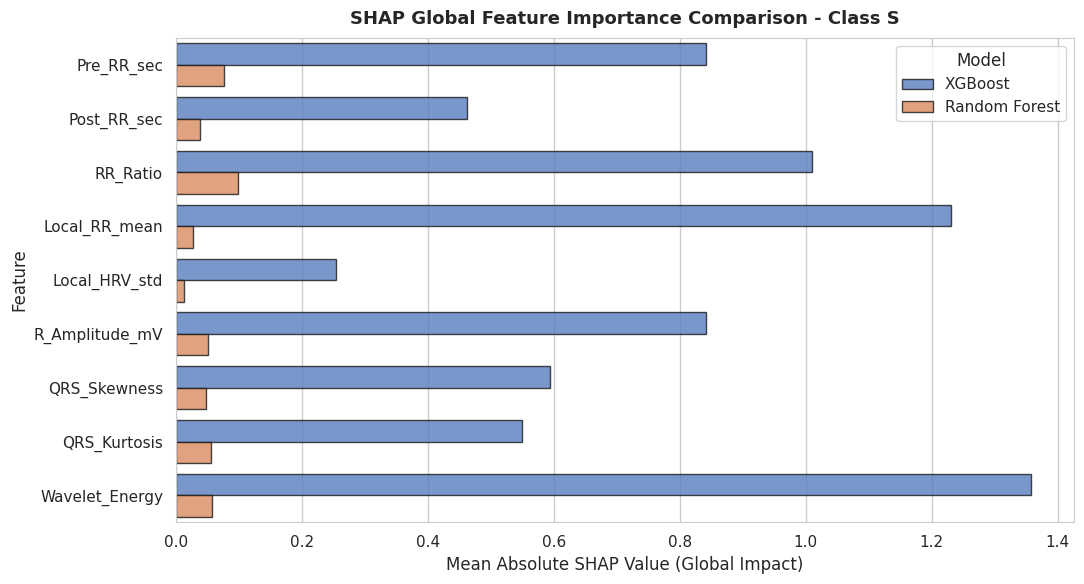

SHAP importance plots saved for class S.


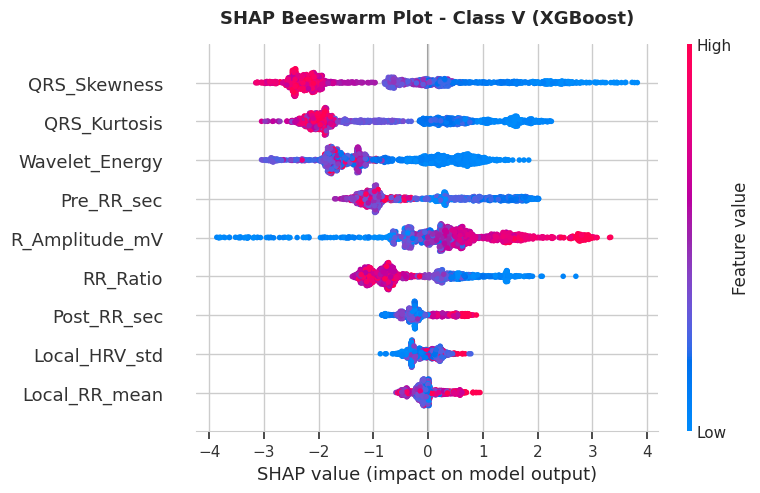

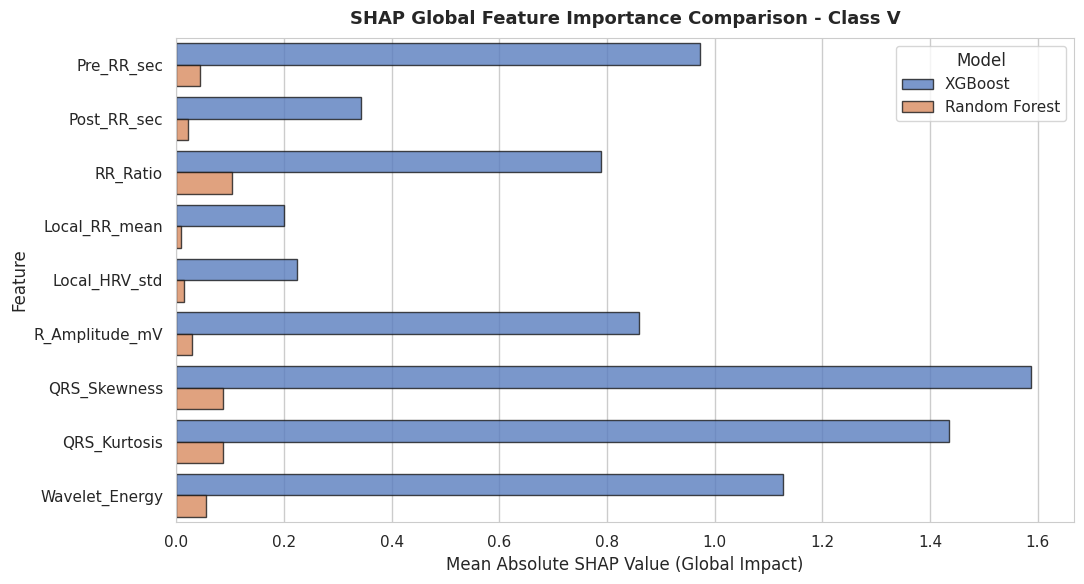

SHAP importance plots saved for class V.


In [25]:
print("--- Calculating SHAP Values for XGBoost ---")
explainer_xgb = shap.TreeExplainer(xgb_clf)
shap_values_xgb = explainer_xgb.shap_values(X_train_resampled)

print("--- Calculating SHAP Values for Random Forest ---")
explainer_rf = shap.TreeExplainer(rf_clf)
shap_values_rf = explainer_rf.shap_values(X_train_resampled)

# Save beeswarm summary plot for XGBoost per class
os.makedirs('../figures/shap', exist_ok=True)

for idx, c_name in enumerate(classes):
    # Plot XGBoost Beeswarm
    plt.figure(figsize=(10, 6))
    shap_vals_class = shap_values_xgb[:, :, idx]
    shap.summary_plot(shap_vals_class, X_train_resampled, feature_names=feature_cols, show=False)
    plt.title(f"SHAP Beeswarm Plot - Class {c_name} (XGBoost)", fontsize=13, fontweight='bold', pad=15)
    plt.tight_layout()
    plt.savefig(f"../figures/shap/shap_beeswarm_{c_name}.png", dpi=150)
    plt.show()
    plt.close()
    
    # Plot Feature Importance Comparison between RF and XGBoost
    mean_abs_xgb = np.mean(np.abs(shap_values_xgb[:, :, idx]), axis=0)
    mean_abs_rf = np.mean(np.abs(shap_values_rf[:, :, idx]), axis=0)
    
    df_compare = pd.DataFrame({
        'Feature': feature_cols * 2,
        'Mean_Abs_SHAP': np.concatenate([mean_abs_xgb, mean_abs_rf]),
        'Model': ['XGBoost'] * len(feature_cols) + ['Random Forest'] * len(feature_cols)
    })
    
    plt.figure(figsize=(11, 6))
    sns.barplot(data=df_compare, y='Feature', x='Mean_Abs_SHAP', hue='Model', palette='muted', edgecolor='k', alpha=0.8)
    plt.title(f"SHAP Global Feature Importance Comparison - Class {c_name}", fontsize=13, fontweight='bold', pad=10)
    plt.xlabel("Mean Absolute SHAP Value (Global Impact)")
    plt.tight_layout()
    plt.savefig(f"../figures/shap/shap_importance_comparison_{c_name}.png", dpi=150)
    plt.show()
    plt.close()
    print(f"SHAP importance plots saved for class {c_name}.")


## 10. Local Explainable AI (Waterfall Plots)
We select individual beats from the test set to explain why the model made certain decisions. We will generate waterfall plots showing the contribution of each feature towards a specific class prediction.

We look for:
1. A **Normal Beat (N)** correctly classified.
2. A **Premature Ventricular Contraction (V)** correctly classified.
3. A **Supraventricular Ectopic Beat (S)** correctly classified.
4. A **Supraventricular Beat (S) misclassified as Normal (N)**.


In [26]:
# Transform scaled test features back to DataFrame for easy querying
df_test_scaled = pd.DataFrame(X_test_scaled, columns=feature_cols)
df_test_scaled['True_Label'] = y_test.values
# Predict labels using XGBoost
df_test_scaled['Pred_Label'] = le.inverse_transform(xgb_clf.predict(X_test_scaled))


In [27]:
# Find indices of the 4 representative samples for local explanations
normal_beats = df_test_scaled[(df_test_scaled['True_Label'] == 'N') & (df_test_scaled['Pred_Label'] == 'N')]
normal_idx = normal_beats.index[0] if not normal_beats.empty else None

vent_beats = df_test_scaled[(df_test_scaled['True_Label'] == 'V') & (df_test_scaled['Pred_Label'] == 'V')]
vent_idx = vent_beats.index[0] if not vent_beats.empty else None

supra_beats = df_test_scaled[(df_test_scaled['True_Label'] == 'S') & (df_test_scaled['Pred_Label'] == 'S')]
supra_idx = supra_beats.index[0] if not supra_beats.empty else None

mis_beats = df_test_scaled[(df_test_scaled['True_Label'] == 'S') & (df_test_scaled['Pred_Label'] == 'N')]
mis_idx = mis_beats.index[0] if not mis_beats.empty else None

print("Representative sample indices selected for local SHAP explanations:")
print(f"Normal: {normal_idx}, Ventricular: {vent_idx}, Supraventricular: {supra_idx}, Misclassified: {mis_idx}")

# Calculate SHAP values ONLY for these specific samples to ensure instant execution
print("--- Calculating SHAP values for selected local instances ---")
selected_indices = [idx for idx in [normal_idx, vent_idx, supra_idx, mis_idx] if idx is not None]
X_test_selected = X_test_scaled[selected_indices]
shap_values_selected = explainer_xgb.shap_values(X_test_selected)

# Helper map to link original index to position in selection
idx_to_pos = {original_idx: pos for pos, original_idx in enumerate(selected_indices)}


Representative sample indices selected for local SHAP explanations:
Normal: 0, Ventricular: 4390, Supraventricular: 6, Misclassified: 16404
--- Calculating SHAP values for selected local instances ---


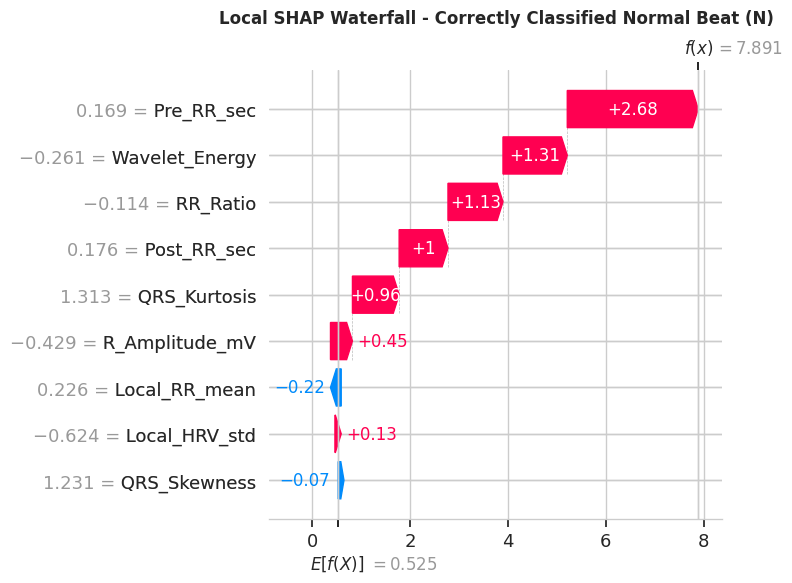

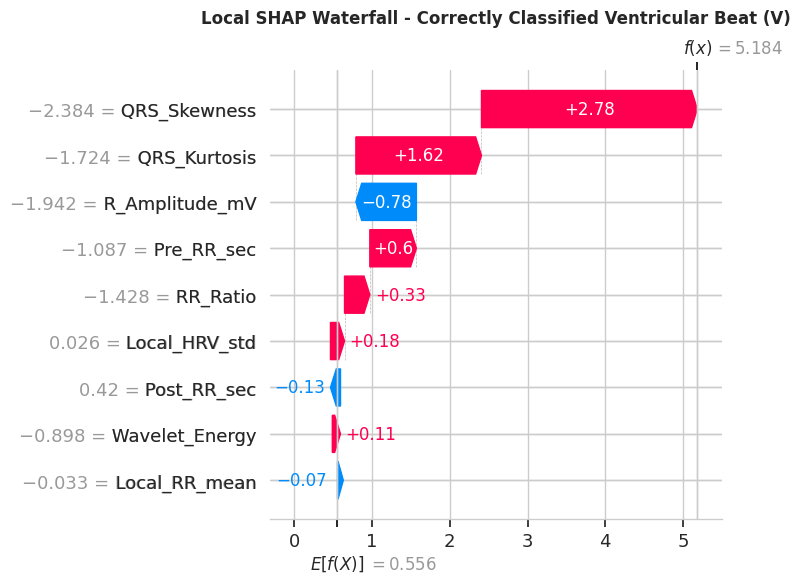

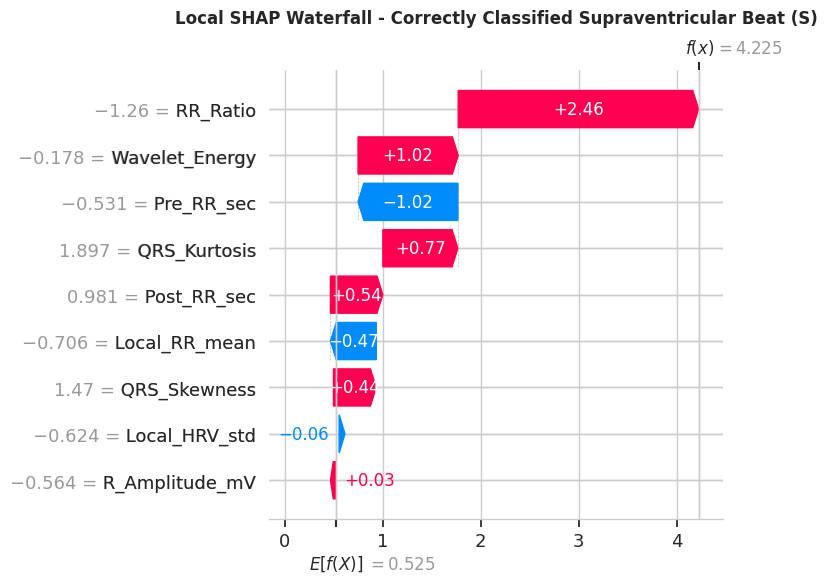

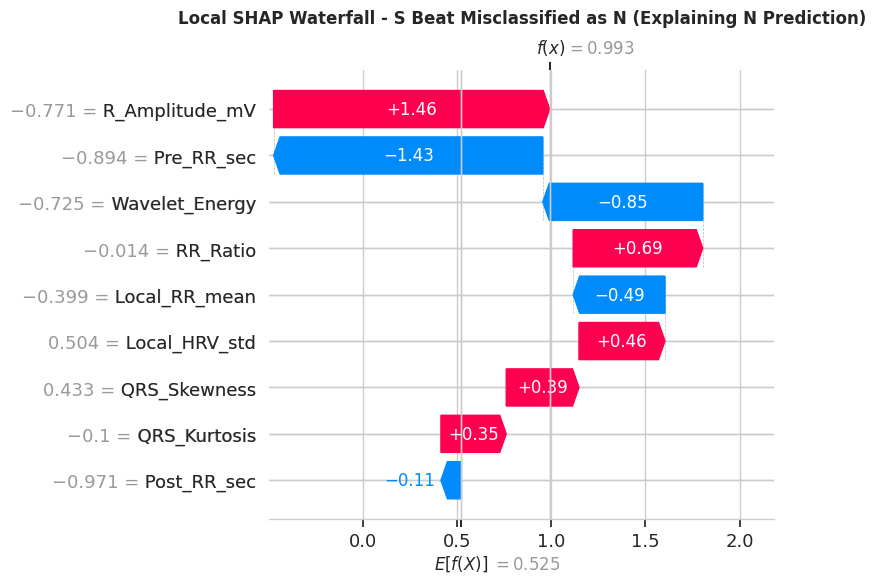


Pipeline execution complete! All plots saved successfully in the '../figures/' folder.


In [28]:
# 1. Correctly Classified Normal Beat (True N, Pred N)
if normal_idx is not None:
    pos = idx_to_pos[normal_idx]
    plt.figure(figsize=(10, 5))
    exp = shap.Explanation(
        values=shap_values_selected[pos, :, 1], # Index 1 is Normal (N)
        base_values=explainer_xgb.expected_value[1],
        data=X_test_scaled[normal_idx],
        feature_names=feature_cols
    )
    shap.waterfall_plot(exp, show=False)
    plt.title("Local SHAP Waterfall - Correctly Classified Normal Beat (N)", fontsize=12, fontweight='bold', pad=10)
    plt.tight_layout()
    plt.savefig('../figures/shap/shap_waterfall_normal.png', dpi=150)
    plt.show()
    plt.close()

# 2. Correctly Classified Ventricular Ectopic Beat (True V, Pred V)
if vent_idx is not None:
    pos = idx_to_pos[vent_idx]
    plt.figure(figsize=(10, 5))
    exp = shap.Explanation(
        values=shap_values_selected[pos, :, 3], # Index 3 is Ventricular (V)
        base_values=explainer_xgb.expected_value[3],
        data=X_test_scaled[vent_idx],
        feature_names=feature_cols
    )
    shap.waterfall_plot(exp, show=False)
    plt.title("Local SHAP Waterfall - Correctly Classified Ventricular Beat (V)", fontsize=12, fontweight='bold', pad=10)
    plt.tight_layout()
    plt.savefig('../figures/shap/shap_waterfall_ventricular.png', dpi=150)
    plt.show()
    plt.close()

# 3. Correctly Classified Supraventricular Beat (True S, Pred S)
if supra_idx is not None:
    pos = idx_to_pos[supra_idx]
    plt.figure(figsize=(10, 5))
    exp = shap.Explanation(
        values=shap_values_selected[pos, :, 2], # Index 2 is Supraventricular (S)
        base_values=explainer_xgb.expected_value[2],
        data=X_test_scaled[supra_idx],
        feature_names=feature_cols
    )
    shap.waterfall_plot(exp, show=False)
    plt.title("Local SHAP Waterfall - Correctly Classified Supraventricular Beat (S)", fontsize=12, fontweight='bold', pad=10)
    plt.tight_layout()
    plt.savefig('../figures/shap/shap_waterfall_supraventricular.png', dpi=150)
    plt.show()
    plt.close()

# 4. Misclassified Supraventricular Beat (True S, Pred N)
if mis_idx is not None:
    pos = idx_to_pos[mis_idx]
    plt.figure(figsize=(10, 5))
    exp = shap.Explanation(
        values=shap_values_selected[pos, :, 1], # explaining Class N
        base_values=explainer_xgb.expected_value[1],
        data=X_test_scaled[mis_idx],
        feature_names=feature_cols
    )
    shap.waterfall_plot(exp, show=False)
    plt.title("Local SHAP Waterfall - S Beat Misclassified as N (Explaining N Prediction)", fontsize=12, fontweight='bold', pad=10)
    plt.tight_layout()
    plt.savefig('../figures/shap/shap_waterfall_misclassified.png', dpi=150)
    plt.show()
    plt.close()
    
print("\nPipeline execution complete! All plots saved successfully in the '../figures/' folder.")
